In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

Charger le dataset

In [2]:
titanic = sns.load_dataset('titanic')
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Repérer les valeurs manquantes

In [3]:
titanic.isna().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


Préparation des données avant l'entraînement d'un modèle\
1. Choisir les colonnes/features pertinentes

In [4]:
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
X = titanic[features]
y = titanic['survived'].values

2. Séparer les données en Train et Test

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

3. Gérer les valeurs manquantes

In [6]:
age_median = X_train['age'].median()
embarked_mode = X_train['embarked'].mode()[0]

X_train = X_train.fillna({'age': age_median, 'embarked': embarked_mode})
X_test = X_test.fillna({'age': age_median, 'embarked': embarked_mode})

print("Valeurs manquantes restantes:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Valeurs manquantes restantes: 0 0


4. Encoder les variables catégorielles

In [7]:
cat = ['sex', 'embarked', 'pclass']

X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0) # mêmes colonnes que le train

X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,28.5,0,0,56.4958,True,False,True,False,True
481,28.5,0,0,0.0000,True,False,True,True,False
527,28.5,0,0,221.7792,True,False,True,False,False
855,18.0,0,1,9.3500,False,False,True,False,True
801,31.0,1,1,26.2500,False,False,True,True,False


5. Normaliser les features numériques

In [8]:
num = ['age', 'fare']
scaler = StandardScaler()

X_train[num] = scaler.fit_transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,-0.081135,0,0,0.513812,True,False,True,False,True
481,-0.081135,0,0,-0.662563,True,False,True,True,False
527,-0.081135,0,0,3.955399,True,False,True,False,False
855,-0.887827,0,1,-0.467874,False,False,True,False,True
801,0.110934,1,1,-0.115977,False,False,True,True,False


6. Conversion en numpy array

In [9]:
feature_names = list(X_train.columns)
X_train = X_train.values.astype('float32')
X_test = X_test.values.astype('float32')

7. Vérifier les dimensions

In [10]:
print("Shape X_train:", X_train.shape)
print("Shape y_train:", y_train.shape)
print("Shape X_test:", X_test.shape)

Shape X_train: (712, 9)
Shape y_train: (712,)
Shape X_test: (179, 9)


8. Construire le modèle avec une architecture de 27 neurones dans la couche cachée

In [11]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(27, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298 (1.16 KB)

 Trainable params: 298 (1.16 KB)

 Non-trainable params: 0 (0.00 B)

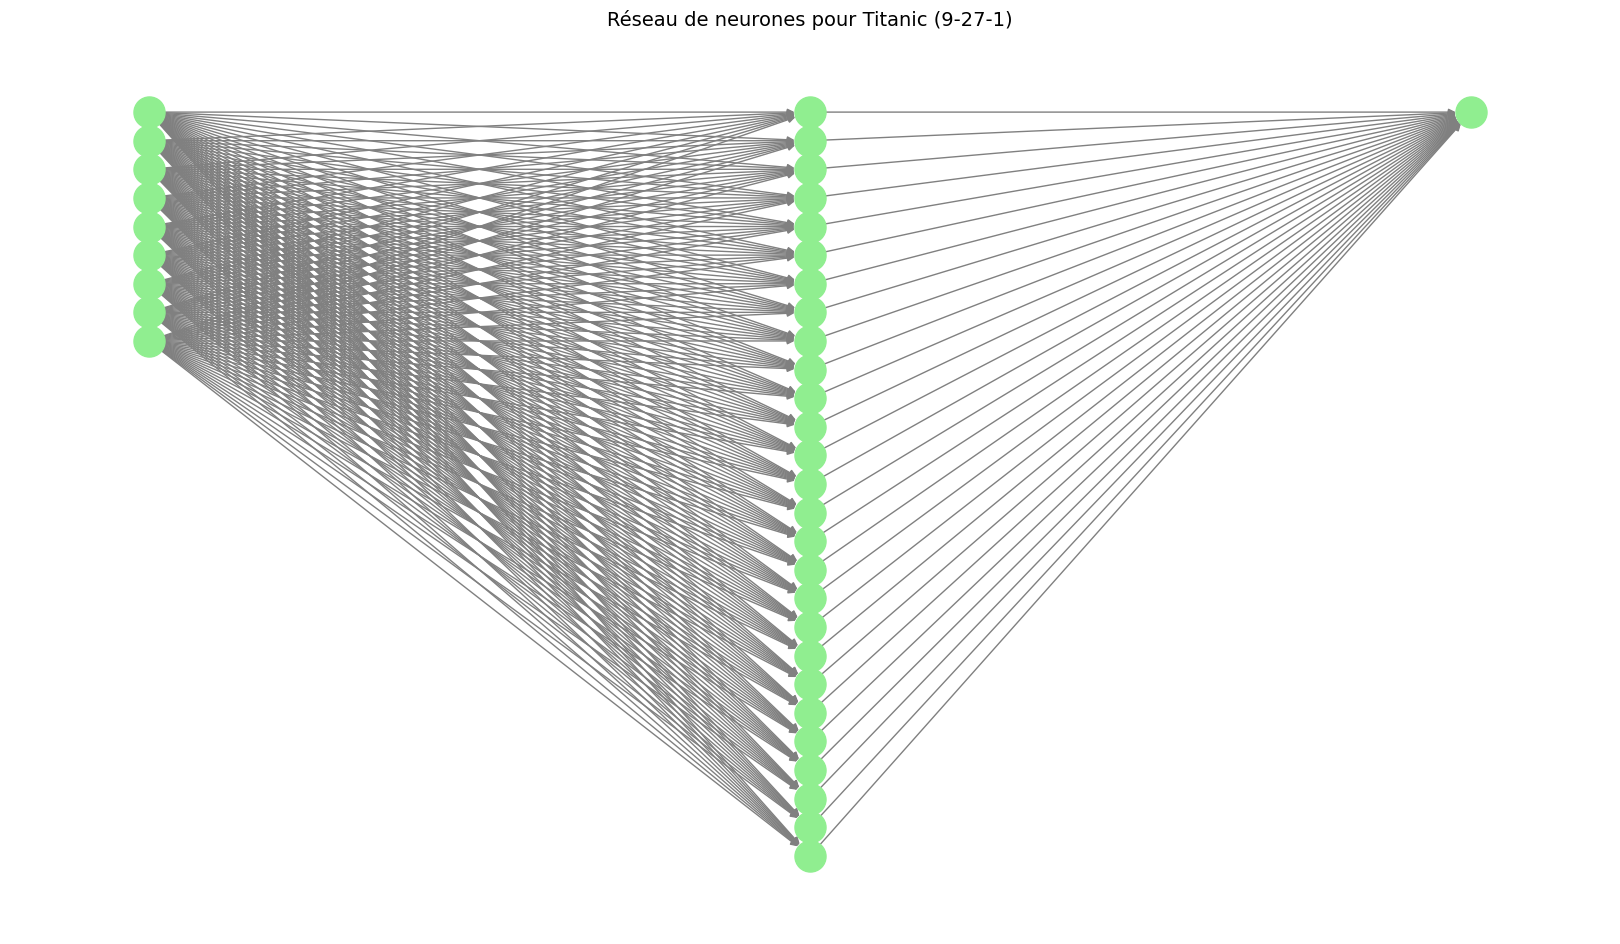

In [16]:
layers = [9, 27, 1]

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i) # Positionner les neurones en colonnes
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

for l in range(len(layers)-1):
    for src in layer_positions[l]:
        for dst in layer_positions[l+1]:
            G.add_edge(src, dst)

plt.figure(figsize=(16, 9))
nx.draw(G, pos, with_labels=False,
        node_size=500, node_color="lightgreen", edge_color="gray")
plt.title("Réseau de neurones pour Titanic (9-27-1)", fontsize=14)
plt.show()

9. Compiler et entraîner le modèle

In [13]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
# L'arrêt anticipé (EarlyStopping) interrompt l'entraînement quand la perte de validation ne baisse plus pendant 10 époques.
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5359 - loss: 0.7170 - val_accuracy: 0.6111 - val_loss: 0.6429
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7063 - loss: 0.6605 - val_accuracy: 0.7917 - val_loss: 0.6031
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7344 - loss: 0.6223 - val_accuracy: 0.8056 - val_loss: 0.5742
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7297 - loss: 0.5947 - val_accuracy: 0.7778 - val_loss: 0.5518
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7234 - loss: 0.5736 - val_accuracy: 0.7917 - val_loss: 0.5326
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7375 - loss: 0.5568 - val_accuracy: 0.7917 - val_loss: 0.5169
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7484 - loss: 0.5427 - val_accuracy: 0.7778 - val_loss: 0.5036
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7547 - loss: 0.5306 - val_accuracy: 0.7778 - val_loss

10. Évaluer le modèle sur le test set

In [14]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8156 - loss: 0.4529 
Test Accuracy: 81.56%


Pour visualiser concrètement les prédictions, création d'un tableau  récapitulatif avec les probabilités.

In [15]:
predictions = model.predict(X_test)
y_pred = (predictions > 0.5).astype(int).ravel()

df_test = pd.DataFrame(X_test, columns=feature_names)
df_test[num] = scaler.inverse_transform(df_test[num])
df_test['age'] = df_test['age'].round(0).astype(int)
df_test['sibsp'] = df_test['sibsp'].astype(int)
df_test['parch'] = df_test['parch'].astype(int)
df_test['fare'] = df_test['fare'].round(2)

df_test["True_Class"] = y_test
df_test["Predicted_Class"] = y_pred
df_test["Proba"] = predictions.ravel().round(3)
df_test['correct'] = df_test['True_Class'] == df_test['Predicted_Class']

df_test.head(10)

df_test['correct'].value_counts()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


,count
correct,
True,146
False,33


Affichage du rapport de classification détaillé

In [17]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179



Conclusion \
Le modèle est globalement juste à 82 %, mais il est "pessimiste" car il y a plus de morts que de survivants dans les données d'entraînement. \
  Les décès (0): Il les détecte presque tous facilement. \
  Les survivants (1): Il en rate beaucoup (il les classe décédés par erreur). Par contre, lorsqu'il annonce qu'un passager a survécu, il a presque toujours raison.